# Phase 5 : profils de clients (Q1)

Ce notebook décrit la population des clients, construit une ligne de variables par client actif, puis regroupe les clients en profils avec K-means. Les fonctions sont dans `src/profiles.py`. Chaque étape est expliquée dans `docs/`.

Les clients sans transaction servent seulement à décrire la population : ils n'ont pas de comportement à résumer (règle de P2-04).

## Chargement des données

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.load_data import load_clean_table
from src.charte import (
    apply_style, save_figure, BLUE, ORANGE, NEUTRAL, TEXT_SECONDARY, THOUSANDS, diverging_cmap,
)
from src.profiles import (
    describe_population, PROFILE_INPUT_COLUMNS, build_profile_table, CLUSTER_VARIABLES,
    prepare_features, scan_kmeans, fit_profiles, profile_medians, profile_zscores,
    distinctive_traits, check_stability,
)

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [2]:
df = load_clean_table("analysis", columns=PROFILE_INPUT_COLUMNS)
df_users = load_clean_table("users")
print(f"Table d'analyse : {len(df):,} transactions ; clients : {len(df_users):,}")

Table d'analyse : 13,305,915 transactions ; clients : 2,000


## P5-01 : décrire la population des clients

Âge, genre, revenus, dette et score de crédit des 2 000 clients, en comparant les clients actifs (au moins une transaction) et les clients sans transaction.

Critère de fin : tableaux et graphiques commentés. Voir `docs/P5-01_population_clients.md`.

In [3]:
actifs = df["client_id"].unique()
population = describe_population(df_users, actifs)
population

statut,actifs,sans transaction
clients,1219.0,781.0
âge médian (février 2020),51.0,28.0
part de femmes (%),51.0,50.4
revenu annuel médian ($),40012.0,41940.0
dette médiane ($),51984.0,65126.0
score de crédit médian,715.0,705.0
cartes de crédit (médiane),4.0,2.0
revenus suspects (P3-08),11.0,4.0


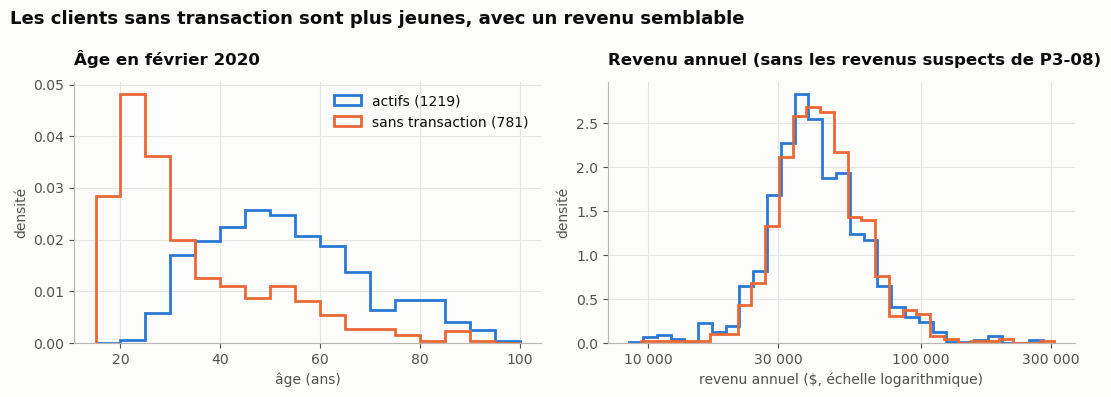

In [4]:
statut = np.where(df_users["id"].isin(actifs), "actifs", "sans transaction")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nom, couleur in [("actifs", BLUE), ("sans transaction", ORANGE)]:
    groupe = df_users[statut == nom]
    axes[0].hist(groupe["current_age"], bins=range(15, 105, 5), histtype="step", linewidth=2,
                 color=couleur, label=f"{nom} ({len(groupe)})", density=True)
    revenus = groupe.loc[groupe["suspicious_income"] == 0, "yearly_income"]
    axes[1].hist(np.log10(revenus), bins=30, histtype="step", linewidth=2, color=couleur, label=nom,
                 density=True)
axes[0].set_title("Âge en février 2020")
axes[0].set_xlabel("âge (ans)")
axes[1].set_title("Revenu annuel (sans les revenus suspects de P3-08)")
axes[1].set_xlabel("revenu annuel ($, échelle logarithmique)")
reperes = [10_000, 30_000, 100_000, 300_000]
axes[1].set_xticks(np.log10(reperes))
axes[1].set_xticklabels(["10 000", "30 000", "100 000", "300 000"])
for ax in axes:
    ax.set_ylabel("densité")
axes[0].legend()
fig.suptitle('Les clients sans transaction sont plus jeunes, avec un revenu semblable', x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_figure(fig, "P5-01_population_clients")
plt.show()

**Constats**

- 1 219 clients sont actifs et 781 n'ont aucune transaction.
- Les clients sans transaction sont beaucoup plus jeunes : âge médian de 28 ans contre 51 ans. Le graphique le confirme : la plupart ont entre 15 et 35 ans.
- Leur revenu annuel médian est proche de celui des actifs (41 940 $ contre 40 012 $), et les deux distributions de revenu se superposent.
- Ils ont une dette médiane plus élevée (65 126 $ contre 51 984 $) et moins de cartes de crédit (médiane de 2 contre 4).
- La part de femmes est la même (50,4 % et 51,0 %). Le score de crédit médian est proche (705 et 715).
- 11 clients actifs et 4 clients sans transaction ont un revenu suspect (P3-08).

## P5-02 : construire les variables de profil

Une ligne par client actif. Variables de dépense : nombre de transactions, transactions par mois d'activité, montant moyen et médian des achats, dépenses par mois, parts en ligne, à l'étranger et de nuit, part de remboursements, taux d'erreur, nombre de cartes et de commerçants. Variables financières : revenu, dette, score de crédit et rapport dette / revenu.

Critère de fin : table des profils créée. Voir `docs/P5-02_variables_profil.md`.

In [5]:
profiles = build_profile_table(df, df_users)
del df
print(f"Table des profils : {profiles.shape[0]:,} clients actifs, {profiles.shape[1]} colonnes")
print("Valeurs vides :", int(profiles.isna().sum().sum()))
profiles.describe().T.round(3)

Table des profils : 1,219 clients actifs, 21 colonnes
Valeurs vides : 0


,count,mean,std,min,25%,50%,75%,max
n_transactions,1219.0,10915.435,5607.355,760.000,7223.500,9832.000,13349.000,48479.000
mean_purchase,1219.0,51.822,19.188,5.592,39.085,48.464,61.689,178.009
median_purchase,1219.0,33.847,19.769,0.320,18.418,31.005,44.660,136.300
share_online,1219.0,0.105,0.114,0.008,0.045,0.065,0.102,0.740
share_foreign,1219.0,0.007,0.008,0.000,0.002,0.004,0.008,0.095
share_night,1219.0,0.058,0.075,0.000,0.015,0.031,0.063,0.527
share_refund,1219.0,0.048,0.037,0.001,0.026,0.040,0.060,0.273
error_rate,1219.0,0.016,0.007,0.002,0.012,0.014,0.017,0.146
n_cards,1219.0,3.340,1.508,1.000,2.000,3.000,4.000,9.000
n_merchants,1219.0,293.435,96.649,56.000,225.000,284.000,351.000,846.000


**Constats**

- La table des profils a 1 219 lignes (une par client actif) et 21 colonnes, sans valeur vide : le critère de fin est validé.
- Un client actif compte en médiane 9 832 transactions (de 760 à 48 479) et 84,9 transactions par mois d'activité.
- Le montant moyen des achats a une médiane de 48,46 $ par client. Les dépenses par mois ont une médiane de 3 881 $.
- La part en ligne a une médiane de 0,065, mais elle monte jusqu'à 0,740 pour certains clients. La part à l'étranger a une médiane de 0,004 et un maximum de 0,095.
- La plupart des clients sont actifs sur les 118 mois (médiane de 118) ; le plus court historique dure 28 mois.

## P5-03 : préparer la segmentation

Les variables candidates sont comparées avec la corrélation de Spearman : deux variables très liées (au-delà de 0,8) apporteraient la même information deux fois. Les variables asymétriques passent par log(1 + x), puis toutes sont mises à la même échelle. Les clients avec un revenu suspect (P3-08) sont écartés de la segmentation : leur revenu fausserait les groupes.

Critère de fin : choix des variables justifié par écrit. Voir `docs/P5-03_preparation_segmentation.md`.

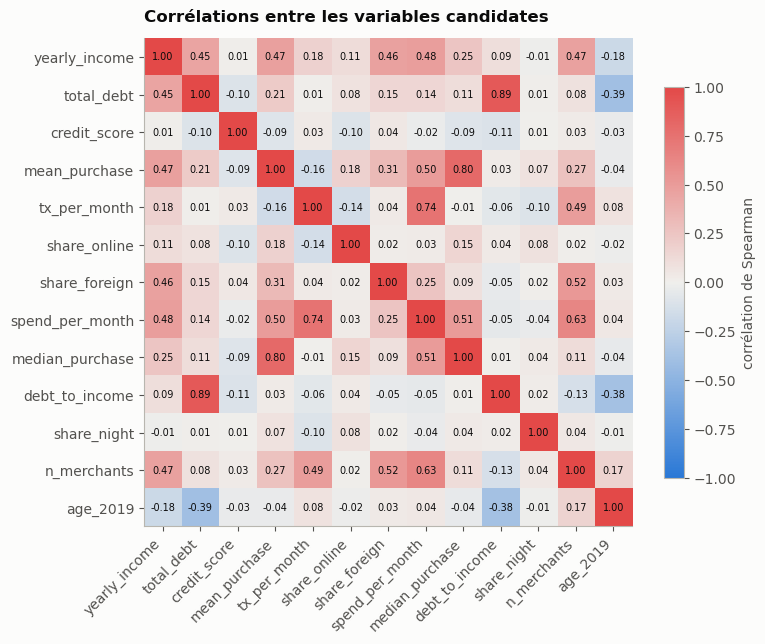

total_debt       debt_to_income     0.89
mean_purchase    median_purchase    0.80
tx_per_month     spend_per_month    0.74
spend_per_month  n_merchants        0.63
share_foreign    n_merchants        0.52
spend_per_month  median_purchase    0.51
Name: corrélation, dtype: float64

In [6]:
candidates = CLUSTER_VARIABLES + ["spend_per_month", "median_purchase", "debt_to_income",
                                  "share_night", "n_merchants", "age_2019"]
correlations = profiles[candidates].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(correlations, cmap=diverging_cmap(), vmin=-1, vmax=1)
ax.set_xticks(range(len(candidates)))
ax.set_xticklabels(candidates, rotation=45, ha="right")
ax.set_yticks(range(len(candidates)))
ax.set_yticklabels(candidates)
ax.grid(False)
for i in range(len(candidates)):
    for j in range(len(candidates)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="corrélation de Spearman")
ax.set_title("Corrélations entre les variables candidates")
fig.tight_layout()
plt.show()

paires = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack()
paires[paires.abs() >= 0.5].sort_values(key=abs, ascending=False).round(2).rename("corrélation")

In [7]:
segmentables = profiles[profiles["suspicious_income"] == 0]
x = prepare_features(segmentables)
print(f"Clients segmentés : {len(x):,} (écartés pour revenu suspect : {len(profiles) - len(x)})")
print("Variables retenues :", CLUSTER_VARIABLES)
x.describe().loc[["mean", "std"]].round(2)

Clients segmentés : 1,208 (écartés pour revenu suspect : 11)
Variables retenues : ['yearly_income', 'total_debt', 'credit_score', 'mean_purchase', 'tx_per_month', 'share_online', 'share_foreign']


,yearly_income,total_debt,credit_score,mean_purchase,tx_per_month,share_online,share_foreign
mean,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Constats**

- Trois paires de variables candidates sont très liées : dette et rapport dette / revenu (0,89), montant moyen et montant médian (0,80), transactions par mois et dépenses par mois (0,74).
- Dans chaque paire, une seule variable est gardée : la dette, le montant moyen et les transactions par mois. Aucune paire des sept variables retenues ne dépasse 0,5.
- Variables retenues : trois financières (revenu, dette, score de crédit) et quatre de dépense (montant moyen, fréquence, part en ligne, part à l'étranger). Le genre et l'âge n'entrent pas dans la segmentation : ils servent seulement à décrire les profils.
- 1 208 clients sont segmentés. 11 sont écartés à cause d'un revenu suspect.
- Après la mise à l'échelle, chaque variable a une moyenne de 0 et un écart-type de 1.

## P5-04 : segmenter les clients avec K-means

K-means est lancé de 2 à 10 groupes. La méthode du coude regarde où l'inertie (distance des clients au centre de leur groupe) cesse de baisser fortement. Le score de silhouette mesure si chaque client est plus proche de son groupe que du groupe voisin (de -1 à 1, plus haut = groupes mieux séparés).

Critère de fin : nombre de groupes justifié. Voir `docs/P5-04_segmentation_kmeans.md`.

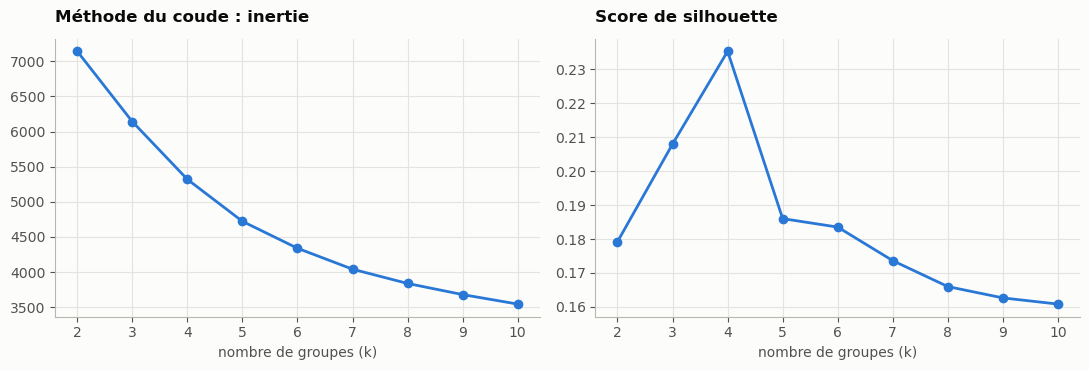

,inertie,silhouette
k,,
2,7140.965,0.179
3,6140.976,0.208
4,5319.832,0.235
5,4722.716,0.186
6,4339.850,0.184
7,4042.083,0.174
8,3839.294,0.166
9,3680.823,0.163
10,3545.867,0.161


In [8]:
scan = scan_kmeans(x)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(scan.index, scan["inertie"], marker="o", color=BLUE)
axes[0].set_title("Méthode du coude : inertie")
axes[1].plot(scan.index, scan["silhouette"], marker="o", color=BLUE)
axes[1].set_title("Score de silhouette")
for ax in axes:
    ax.set_xlabel("nombre de groupes (k)")
    ax.set_xticks(scan.index)
fig.tight_layout()
save_figure(fig, "P5-04_choix_nombre_groupes")
plt.show()
scan.round(3)

In [9]:
# Choix justifié dans les constats ci-dessous
k_choisi = 4
labels = fit_profiles(x, k_choisi)
pd.Series(labels).value_counts().sort_index().rename("clients par profil")

1    686
2    321
3    138
4     63
Name: clients par profil, dtype: int64

**Constats**

- Le score de silhouette est le plus haut avec 4 groupes (0,235), devant 3 groupes (0,208) et 5 groupes (0,186). Au-delà de 5 groupes, il baisse encore.
- L'inertie baisse régulièrement, de 7 141 (2 groupes) à 3 546 (10 groupes). La courbe n'a pas de coude net. La baisse ralentit après 4 groupes (5 320, puis 4 723 avec 5 groupes).
- Choix : 4 groupes. C'est le meilleur score de silhouette, et chaque groupe reste assez grand pour être décrit.
- Tailles des groupes : 686, 321, 138 et 63 clients.

## P5-05 : décrire et nommer chaque profil

Pour chaque profil : taille, valeurs médianes et traits distinctifs. Un trait est distinctif quand la moyenne du profil est à plus d'un demi écart-type de la moyenne de tous les clients.

Critère de fin : une fiche par profil. Voir `docs/P5-05_fiches_profils.md`.

In [10]:
description = ["n_transactions", "tx_per_month", "mean_purchase", "spend_per_month", "share_online",
               "share_foreign", "share_night", "yearly_income", "total_debt", "debt_to_income",
               "credit_score", "age_2019", "n_cards", "n_merchants"]
medianes = profile_medians(segmentables, labels, description)
zscores = profile_zscores(x, labels)
noms_fr = {"yearly_income": ("revenu", False), "total_debt": ("dette", True),
           "credit_score": ("score de crédit", False), "mean_purchase": ("montant moyen", False),
           "tx_per_month": ("fréquence", True), "share_online": ("part en ligne", True),
           "share_foreign": ("part à l'étranger", True)}
traits = distinctive_traits(zscores, noms_fr)
part_femmes = (segmentables.assign(profil=labels).groupby("profil")["gender"]
               .apply(lambda g: round(100 * (g == "Female").mean(), 1)).rename("part de femmes (%)"))
medianes.join(part_femmes).T.round(3)

profil,1,2,3,4
clients,686.000,321.000,138.000,63.000
n_transactions,8737.500,10520.000,15458.500,11003.000
tx_per_month,75.104,90.542,131.407,94.093
mean_purchase,45.018,67.166,42.934,45.516
spend_per_month,3068.721,5611.226,5571.267,4197.183
share_online,0.058,0.066,0.352,0.055
share_foreign,0.003,0.010,0.003,0.004
share_night,0.030,0.034,0.028,0.028
yearly_income,34928.500,59872.000,42102.000,39809.000
total_debt,47568.500,87082.000,54528.000,0.000


In [11]:
# Noms donnés après lecture des fiches
noms_profils = {1: 'Clients courants', 2: 'Clients aisés et voyageurs', 3: 'Acheteurs en ligne très actifs', 4: 'Clients sans dette'}
for profil, row in medianes.iterrows():
    print(f"Profil {profil} : {noms_profils[profil]} ({int(row['clients'])} clients)")
    print(f"  {traits[profil]}")

Profil 1 : Clients courants (686 clients)
  proche de la moyenne
Profil 2 : Clients aisés et voyageurs (321 clients)
  revenu élevé (+1,0) ; montant moyen élevé (+0,9) ; part à l'étranger élevée (+0,8)
Profil 3 : Acheteurs en ligne très actifs (138 clients)
  part en ligne élevée (+2,3) ; fréquence élevée (+1,0)
Profil 4 : Clients sans dette (63 clients)
  dette faible (-3,7)


In [12]:
profils_clients = profiles.copy()
profils_clients["profil"] = 0
profils_clients.loc[segmentables.index, "profil"] = labels
noms_complets = {0: "Revenu suspect (non classé)", **noms_profils}
profils_clients["profil_nom"] = profils_clients["profil"].map(noms_complets)
profils_clients.reset_index().rename(columns={"index": "client_id"}).to_parquet(
    "data/clean/client_profiles.parquet", index=False)
fiches = pd.DataFrame({
    "profil": medianes.index,
    "profil_nom": [noms_profils[p] for p in medianes.index],
    "clients": medianes["clients"].astype(int).to_numpy(),
    "revenu_median": medianes["yearly_income"].to_numpy(),
    "transactions_par_mois": medianes["tx_per_month"].to_numpy(),
    "achat_moyen": medianes["mean_purchase"].to_numpy(),
    "traits": [traits[p] for p in medianes.index],
})
fiches.to_parquet("data/clean/profile_sheets.parquet", index=False)
profils_clients["profil_nom"].value_counts()

Clients courants                  686
Clients aisés et voyageurs        321
Acheteurs en ligne très actifs    138
Clients sans dette                 63
Revenu suspect (non classé)        11
Name: profil_nom, dtype: int64

**Constats**

- **Clients courants** (686 clients) : proches de la moyenne sur toutes les variables. Revenu médian de 34 928 $, 75 transactions par mois, achat moyen de 45,02 $, part en ligne de 0,058.
- **Clients aisés et voyageurs** (321 clients) : revenu élevé (59 872 $), achat moyen élevé (67,17 $) et part à l'étranger plus forte (0,010). Ils fréquentent le plus de commerçants (353 en médiane).
- **Acheteurs en ligne très actifs** (138 clients) : part en ligne de 0,352, environ six fois celle des autres profils, et 131 transactions par mois.
- **Clients sans dette** (63 clients) : dette nulle et score de crédit le plus haut (733). C'est le profil où la part de femmes est la plus forte (58,7 %).
- L'âge médian est le même dans les quatre profils (50 ou 51 ans), comme le nombre médian de cartes (3) : les profils se distinguent par les finances et les habitudes, pas par l'âge.
- Les 11 clients au revenu suspect restent hors profils (« Revenu suspect (non classé) »).